<a href="https://colab.research.google.com/github/vaishnavii-25/Corporate-Bankruptcy-Prediction/blob/main/Corporate_Bankruptcy_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# STEP 1: Import Libraries and Load Dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.io import arff

data, metadata = arff.loadarff('/content/3year.arff')

df = pd.DataFrame(data)

df['class'] = df['class'].astype(int)

print("Dataset Shape:", df.shape)
print("\nTotal Companies:", len(df))
print("\nNumber of Features:", df.shape[1] - 1)

df.head()

Dataset Shape: (10503, 65)

Total Companies: 10503

Number of Features: 64


,Attr1,Attr2,Attr3,Attr4,Attr5,Attr6,Attr7,Attr8,Attr9,Attr10,...,Attr56,Attr57,Attr58,Attr59,Attr60,Attr61,Attr62,Attr63,Attr64,class
0,0.174190,0.41299,0.14371,1.3480,-28.9820,0.60383,0.219460,1.1225,1.1961,0.46359,...,0.163960,0.375740,0.83604,0.000007,9.7145,6.2813,84.291,4.3303,4.0341,0
1,0.146240,0.46038,0.28230,1.6294,2.5952,0.00000,0.171850,1.1721,1.6018,0.53962,...,0.027516,0.271000,0.90108,0.000000,5.9882,4.1103,102.190,3.5716,5.9500,0
2,0.000595,0.22612,0.48839,3.1599,84.8740,0.19114,0.004572,2.9881,1.0077,0.67566,...,0.007639,0.000881,0.99236,0.000000,6.7742,3.7922,64.846,5.6287,4.4581,0
3,0.024526,0.43236,0.27546,1.7833,-10.1050,0.56944,0.024526,1.3057,1.0509,0.56453,...,0.048398,0.043445,0.95160,0.142980,4.2286,5.0528,98.783,3.6950,3.4844,0
4,0.188290,0.41504,0.34231,1.9279,-58.2740,0.00000,0.233580,1.4094,1.3393,0.58496,...,0.176480,0.321880,0.82635,0.073039,2.5912,7.0756,100.540,3.6303,4.6375,0


In [ ]:
# STEP 2A: Data Exploration

print("Total Missing Values:", df.isnull().sum().sum())

print("\nMissing Values in Each Column:")
print(df.isnull().sum()[df.isnull().sum() > 0])

print("\nDuplicate Records:", df.duplicated().sum())

print("\nBankruptcy Class Distribution:")
print(df['class'].value_counts())

print("\nClass Distribution Percentage:")
print(df['class'].value_counts(normalize=True) * 100)

Total Missing Values: 9888

Missing Values in Each Column:
Attr4       18
Attr5       25
Attr8       14
Attr9        3
Attr12      18
Attr13      43
Attr15       8
Attr16      14
Attr17      14
Attr19      43
Attr20      43
Attr21     807
Attr23      43
Attr24     227
Attr26      14
Attr27     715
Attr28     228
Attr30      43
Attr31      43
Attr32     101
Attr33      18
Attr34      14
Attr37    4736
Attr39      43
Attr40      18
Attr41     202
Attr42      43
Attr43      43
Attr44      43
Attr45     591
Attr46      18
Attr47      86
Attr49      43
Attr50      14
Attr52      86
Attr53     228
Attr54     228
Attr56      43
Attr58      29
Attr60     592
Attr61      17
Attr62      43
Attr63      18
Attr64     228
dtype: int64

Duplicate Records: 87

Bankruptcy Class Distribution:
class
0    10008
1      495
Name: count, dtype: int64

Class Distribution Percentage:
class
0    95.287061
1     4.712939
Name: proportion, dtype: float64


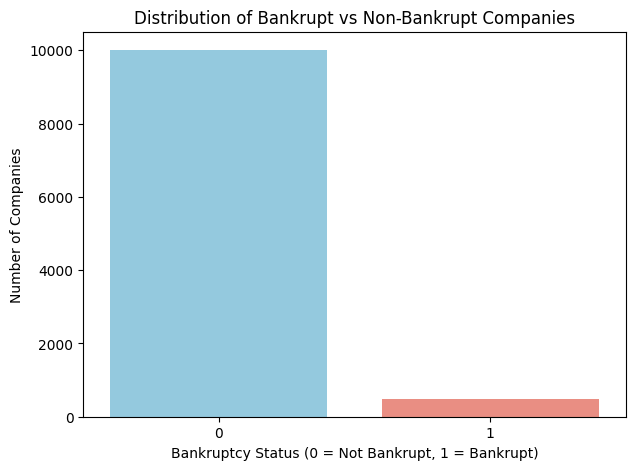

In [ ]:
# STEP 2B: Visualize Bankruptcy Distribution

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='class',
    hue='class',
    palette=['skyblue', 'salmon'],
    legend=False
)

plt.title('Distribution of Bankrupt vs Non-Bankrupt Companies')
plt.xlabel('Bankruptcy Status (0 = Not Bankrupt, 1 = Bankrupt)')
plt.ylabel('Number of Companies')

plt.show()

In [ ]:
# STEP 3A: Separate Features and Target, Train-Test Split

from sklearn.model_selection import train_test_split

X = df.drop('class', axis=1)
y = df['class']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("\nTraining Class Distribution:")
print(y_train.value_counts())

print("\nTesting Class Distribution:")
print(y_test.value_counts())

Training Data Shape: (8402, 64)
Testing Data Shape: (2101, 64)

Training Class Distribution:
class
0    8006
1     396
Name: count, dtype: int64

Testing Class Distribution:
class
0    2002
1      99
Name: count, dtype: int64


In [ ]:
# STEP 3B: Missing Value Imputation and Feature Scaling

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

X_train = X_train.replace([np.inf, -np.inf], np.nan)
X_test = X_test.replace([np.inf, -np.inf], np.nan)

imputer = SimpleImputer(strategy='median')

X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

print("Missing values in training data:",
      np.isnan(X_train_scaled).sum())

print("Missing values in testing data:",
      np.isnan(X_test_scaled).sum())

print("\nTraining Data Shape:", X_train_scaled.shape)
print("Testing Data Shape:", X_test_scaled.shape)

print("\nData preprocessing completed successfully!")

Missing values in training data: 0
Missing values in testing data: 0

Training Data Shape: (8402, 64)
Testing Data Shape: (2101, 64)

Data preprocessing completed successfully!


In [ ]:
# STEP 4A: Logistic Regression

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

# Create model
lr_model = LogisticRegression(
    max_iter=2000,
    class_weight='balanced',
    random_state=42
)

# Train model
lr_model.fit(X_train_scaled, y_train)

# Predict
lr_pred = lr_model.predict(X_test_scaled)

# Evaluate
print("LOGISTIC REGRESSION RESULTS")
print("\nClassification Report:")
print(classification_report(y_test, lr_pred, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, lr_pred))

LOGISTIC REGRESSION RESULTS

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.66      0.79      2002
           1       0.09      0.72      0.17        99

    accuracy                           0.66      2101
   macro avg       0.54      0.69      0.48      2101
weighted avg       0.94      0.66      0.76      2101


Confusion Matrix:
[[1315  687]
 [  28   71]]


In [ ]:
# STEP 4B: Support Vector Machine

from sklearn.svm import SVC

# Create SVM model
svm_model = SVC(
    kernel='rbf',
    class_weight='balanced',
    probability=True,
    random_state=42
)

# Train model
svm_model.fit(X_train_scaled, y_train)

# Predict
svm_pred = svm_model.predict(X_test_scaled)

# Evaluate
print("SVM RESULTS")

print("\nClassification Report:")
print(classification_report(y_test, svm_pred, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, svm_pred))

SVM RESULTS

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.65      0.78      2002
           1       0.10      0.76      0.17        99

    accuracy                           0.65      2101
   macro avg       0.54      0.70      0.48      2101
weighted avg       0.94      0.65      0.75      2101


Confusion Matrix:
[[1295  707]
 [  24   75]]


In [ ]:
# STEP 6C: Random Forest

from sklearn.ensemble import RandomForestClassifier

# Create model
rf_model = RandomForestClassifier(
    n_estimators=200,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

# Train model
rf_model.fit(X_train_imputed, y_train)

# Predict
rf_pred = rf_model.predict(X_test_imputed)

# Evaluate
print("RANDOM FOREST RESULTS")

print("\nClassification Report:")
print(classification_report(y_test, rf_pred, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_pred))

RANDOM FOREST RESULTS

Classification Report:
              precision    recall  f1-score   support

           0       0.96      1.00      0.98      2002
           1       0.79      0.11      0.19        99

    accuracy                           0.96      2101
   macro avg       0.87      0.55      0.59      2101
weighted avg       0.95      0.96      0.94      2101


Confusion Matrix:
[[1999    3]
 [  88   11]]


In [ ]:
!pip install -q xgboost

In [ ]:
# STEP 4D: XGBoost

from xgboost import XGBClassifier

# Calculate class imbalance ratio
negative = (y_train == 0).sum()
positive = (y_train == 1).sum()

scale_weight = negative / positive

print("Scale Pos Weight:", scale_weight)

# Create model
xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=4,
    learning_rate=0.05,
    scale_pos_weight=scale_weight,
    eval_metric='logloss',
    random_state=42
)

# Train model
xgb_model.fit(X_train_imputed, y_train)

# Predict
xgb_pred = xgb_model.predict(X_test_imputed)

# Evaluate
print("XGBOOST RESULTS")

print("\nClassification Report:")
print(classification_report(y_test, xgb_pred, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, xgb_pred))

Scale Pos Weight: 20.217171717171716
XGBOOST RESULTS

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.94      0.96      2002
           1       0.37      0.67      0.48        99

    accuracy                           0.93      2101
   macro avg       0.68      0.81      0.72      2101
weighted avg       0.95      0.93      0.94      2101


Confusion Matrix:
[[1891  111]
 [  33   66]]


In [ ]:
# STEP 5A: Model Performance Comparison

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score
)

# Store models and predictions
models = {
    'Logistic Regression': (lr_model, lr_pred, X_test_scaled),
    'SVM': (svm_model, svm_pred, X_test_scaled),
    'Random Forest': (rf_model, rf_pred, X_test_imputed),
    'XGBoost': (xgb_model, xgb_pred, X_test_imputed)
}

results = []

for name, (model, predictions, test_data) in models.items():

    probabilities = model.predict_proba(test_data)[:, 1]

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, predictions),
        'Precision': precision_score(y_test, predictions, zero_division=0),
        'Recall': recall_score(y_test, predictions, zero_division=0),
        'F1 Score': f1_score(y_test, predictions, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, probabilities),
        'PR-AUC': average_precision_score(y_test, probabilities)
    })

results_df = pd.DataFrame(results)

# Display results
print("MODEL PERFORMANCE COMPARISON")
display(results_df.round(4))

MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.6597,0.0937,0.7172,0.1657,0.7419,0.1327
1,SVM,0.6521,0.0959,0.7576,0.1703,0.7471,0.1330
2,Random Forest,0.9567,0.7857,0.1111,0.1947,0.8602,0.3880
3,XGBoost,0.9315,0.3729,0.6667,0.4783,0.9147,0.6174


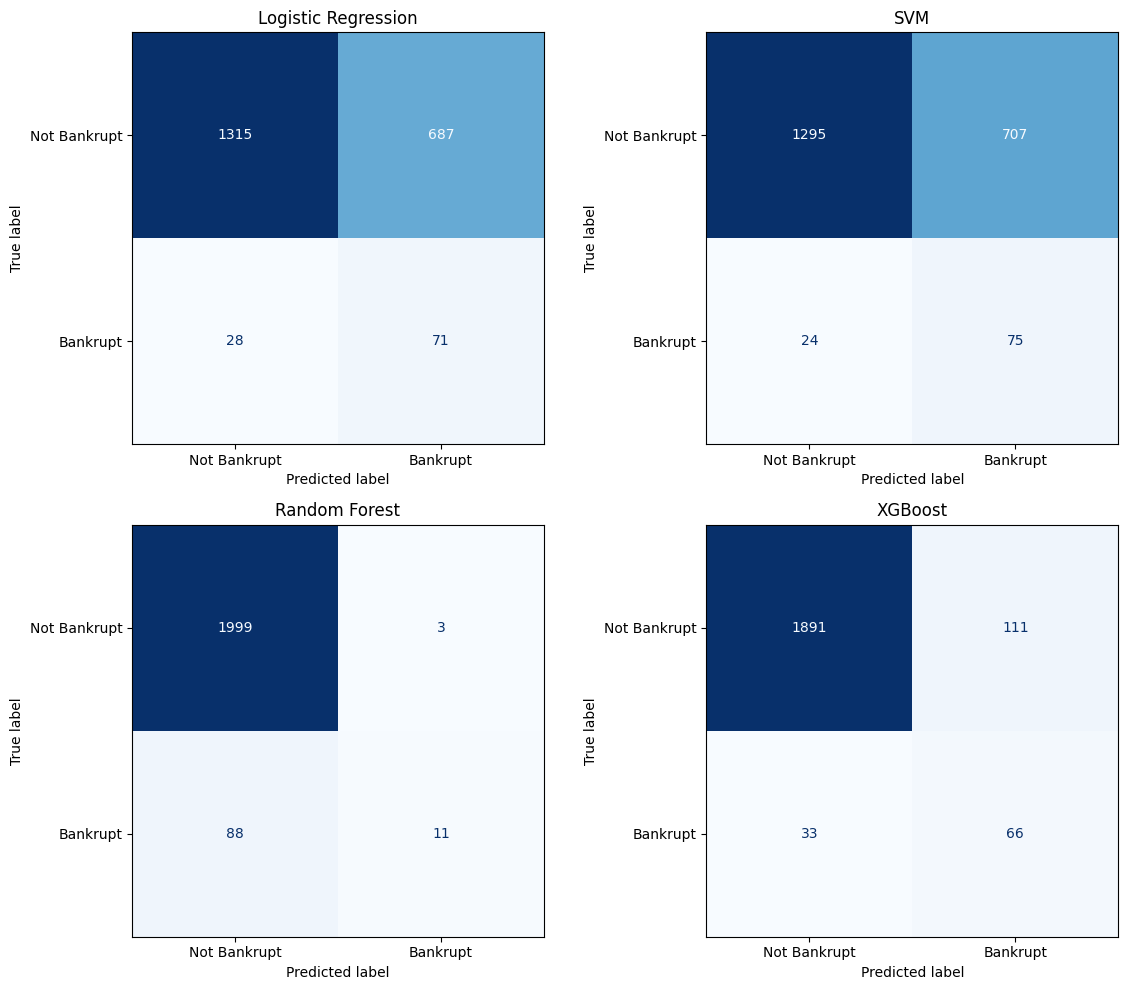

In [ ]:
# STEP 5B: Confusion Matrix Visualization

from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, (name, (model, predictions, test_data)) in zip(
    axes.ravel(), models.items()
):

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        display_labels=['Not Bankrupt', 'Bankrupt'],
        cmap='Blues',
        ax=ax,
        colorbar=False
    )

    ax.set_title(name)

plt.tight_layout()
plt.savefig('confusion_matrices.png', dpi=300, bbox_inches='tight')
plt.show()

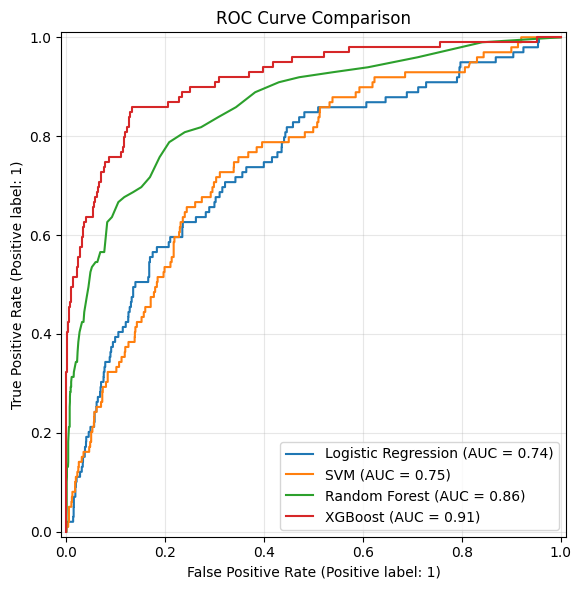

In [ ]:
# STEP 5C: ROC Curve Comparison

from sklearn.metrics import RocCurveDisplay

plt.figure(figsize=(8, 6))

ax = plt.gca()

for name, (model, predictions, test_data) in models.items():

    RocCurveDisplay.from_estimator(
        model,
        test_data,
        y_test,
        name=name,
        ax=ax
    )

plt.title('ROC Curve Comparison')
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig('roc_curves.png', dpi=300, bbox_inches='tight')
plt.show()

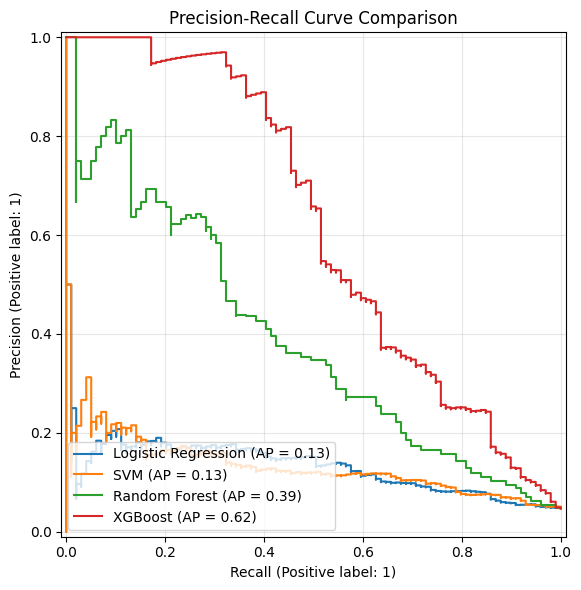

In [ ]:
# STEP 5D: Precision-Recall Curve Comparison
import matplotlib.pyplot as plt
from sklearn.metrics import PrecisionRecallDisplay

plt.figure(figsize=(8, 6))

ax = plt.gca()

for name, (model, predictions, test_data) in models.items():

    PrecisionRecallDisplay.from_estimator(
        model,
        test_data,
        y_test,
        name=name,
        ax=ax
    )

plt.title('Precision-Recall Curve Comparison')
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig('precision_recall_curves.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
# STEP 6A: Select the Best Performing Model

# Rank models based on PR-AUC
sorted_results = results_df.sort_values(
    by='PR-AUC',
    ascending=False
)

print("MODEL PERFORMANCE RANKING:")
display(sorted_results.round(4))

best_model_name = sorted_results.iloc[0]['Model']

print("\nBest Performing Model:", best_model_name)
print("Selection Criteria: Highest PR-AUC")

MODEL PERFORMANCE RANKING:


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
3,XGBoost,0.9315,0.3729,0.6667,0.4783,0.9147,0.6174
2,Random Forest,0.9567,0.7857,0.1111,0.1947,0.8602,0.3880
1,SVM,0.6521,0.0959,0.7576,0.1703,0.7471,0.1330
0,Logistic Regression,0.6597,0.0937,0.7172,0.1657,0.7419,0.1327



Best Performing Model: XGBoost
Selection Criteria: Highest PR-AUC


TOP 10 IMPORTANT FINANCIAL FEATURES:


,Feature,Importance
26,Attr27,0.060149
23,Attr24,0.054200
25,Attr26,0.038570
45,Attr46,0.034171
15,Attr16,0.034145
33,Attr34,0.029901
12,Attr13,0.029007
4,Attr5,0.021651
20,Attr21,0.019402
5,Attr6,0.019250


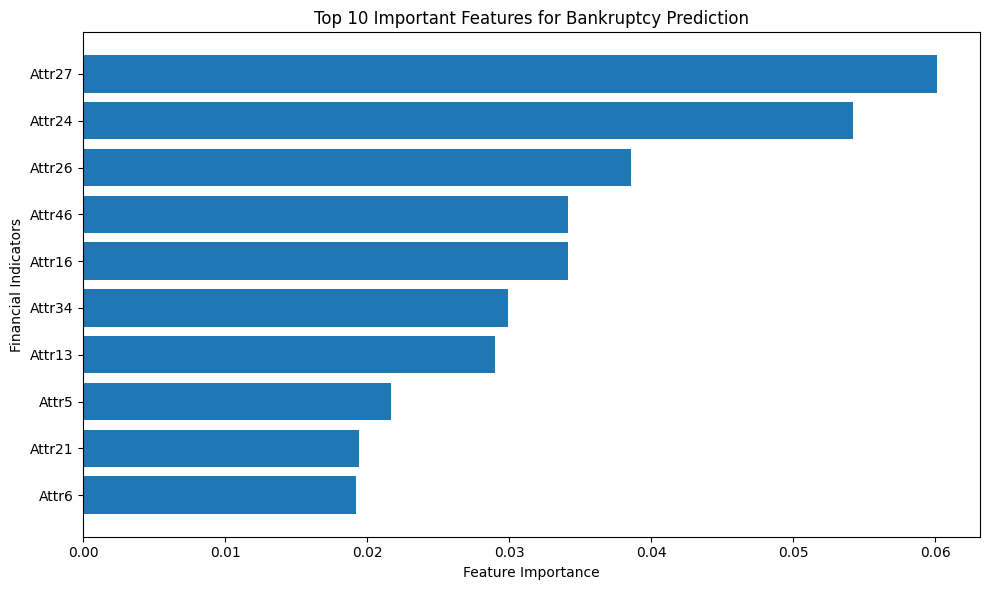

In [ ]:
# STEP 6B: Feature Importance Analysis

import pandas as pd
import matplotlib.pyplot as plt


feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model.feature_importances_
})


feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print("TOP 10 IMPORTANT FINANCIAL FEATURES:")
display(feature_importance.head(10))

plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance.head(10)['Feature'][::-1],
    feature_importance.head(10)['Importance'][::-1]
)

plt.xlabel('Feature Importance')
plt.ylabel('Financial Indicators')
plt.title('Top 10 Important Features for Bankruptcy Prediction')

plt.tight_layout()
plt.savefig('feature_importance.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
# STEP 6C: Save Best Model

import joblib

# Store trained models
model_objects = {
    'Logistic Regression': lr_model,
    'SVM': svm_model,
    'Random Forest': rf_model,
    'XGBoost': xgb_model
}


best_model = model_objects[best_model_name]

joblib.dump(best_model, 'best_bankruptcy_model.pkl')

joblib.dump(imputer, 'imputer.pkl')
joblib.dump(scaler, 'scaler.pkl')

joblib.dump(list(X.columns), 'feature_names.pkl')

print("Best Model Saved Successfully!")
print("Selected Model:", best_model_name)

Best Model Saved Successfully!
Selected Model: XGBoost


In [ ]:
# STEP 6D: Download Saved Files

from google.colab import files

files.download('best_bankruptcy_model.pkl')
files.download('imputer.pkl')
files.download('scaler.pkl')
files.download('feature_names.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# STEP 7A: Bankruptcy Prediction Demonstration

import pandas as pd
import numpy as np

sample_indices = y_test.sample(
    n=10,
    random_state=42
).index

sample_companies = X_test.loc[sample_indices]

sample_companies = sample_companies.replace(
    [np.inf, -np.inf], np.nan
)

sample_imputed = imputer.transform(sample_companies)

sample_probabilities = best_model.predict_proba(sample_imputed)[:, 1]

sample_predictions = best_model.predict(sample_imputed)

prediction_results = pd.DataFrame({
    'Company': range(1, 11),
    'Actual Status': y_test.loc[sample_indices].values,
    'Predicted Status': sample_predictions,
    'Bankruptcy Probability (%)': np.round(
        sample_probabilities * 100, 2
    )
})

prediction_results['Actual Status'] = prediction_results[
    'Actual Status'
].map({0: 'Not Bankrupt', 1: 'Bankrupt'})

prediction_results['Predicted Status'] = prediction_results[
    'Predicted Status'
].map({0: 'Not Bankrupt', 1: 'Bankrupt'})

print("BANKRUPTCY PREDICTION RESULTS")
display(prediction_results)

BANKRUPTCY PREDICTION RESULTS


,Company,Actual Status,Predicted Status,Bankruptcy Probability (%)
0,1,Not Bankrupt,Not Bankrupt,47.990002
1,2,Bankrupt,Bankrupt,89.519997
2,3,Not Bankrupt,Not Bankrupt,14.980000
3,4,Not Bankrupt,Not Bankrupt,43.139999
4,5,Not Bankrupt,Not Bankrupt,17.330000
5,6,Not Bankrupt,Not Bankrupt,7.480000
6,7,Not Bankrupt,Not Bankrupt,14.530000
7,8,Not Bankrupt,Not Bankrupt,2.370000
8,9,Not Bankrupt,Not Bankrupt,4.300000
9,10,Not Bankrupt,Not Bankrupt,3.800000


In [ ]:
# STEP 7B: Predict One Bankrupt and One Non-Bankrupt Company

bankrupt_index = y_test[y_test == 1].index[0]

safe_index = y_test[y_test == 0].index[0]

demo_indices = [safe_index, bankrupt_index]

demo_companies = X_test.loc[demo_indices]

demo_companies = demo_companies.replace(
    [np.inf, -np.inf], np.nan
)

demo_imputed = imputer.transform(demo_companies)

demo_predictions = best_model.predict(demo_imputed)

demo_probabilities = best_model.predict_proba(
    demo_imputed
)[:, 1]

for i, index in enumerate(demo_indices):

    actual = "Bankrupt" if y_test.loc[index] == 1 else "Not Bankrupt"

    predicted = (
        "Bankrupt"
        if demo_predictions[i] == 1
        else "Not Bankrupt"
    )

    print(f"\nCompany {i+1}")
    print("Actual Status:", actual)
    print("Predicted Status:", predicted)
    print(
        "Estimated Bankruptcy Probability:",
        round(demo_probabilities[i] * 100, 2), "%"
    )


Company 1
Actual Status: Not Bankrupt
Predicted Status: Not Bankrupt
Estimated Bankruptcy Probability: 6.01 %

Company 2
Actual Status: Bankrupt
Predicted Status: Bankrupt
Estimated Bankruptcy Probability: 89.88 %


In [ ]:
# STEP 7C: Save Prediction Results

prediction_results.to_csv(
    'bankruptcy_predictions.csv',
    index=False
)

print("Prediction results saved successfully!")

Prediction results saved successfully!
